Multiple Regression analysis with the help of dummy data

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
sns.set()

Import the data into dataFrame

In [11]:
raw_data = pd.read_csv('Dummies_data.csv')
raw_data.head()

,SAT,GPA,Attendance
0,1714,2.40,No
1,1664,2.52,No
2,1760,2.54,No
3,1685,2.74,No
4,1693,2.83,No


We take dummy variable when we have categorical data in our dataset so we basically convert that categorical data into numerical data

In [12]:
data = raw_data.copy()
data.head()

,SAT,GPA,Attendance
0,1714,2.40,No
1,1664,2.52,No
2,1760,2.54,No
3,1685,2.74,No
4,1693,2.83,No


In [13]:
data['Attendance'].unique()

array(['No', 'Yes'], dtype=object)

Attendance column contains two unique values yes and no (Yes = student have more than 75% attendence) and (No = student do not have more than 75% attendence). So, we are going to map this data in numarical form.

In [14]:
data['Attendance'] = data['Attendance'].map({'Yes': 1, 'No': 0})


In [15]:
data['Attendance']

0     0
1     0
2     0
3     0
4     0
     ..
79    1
80    1
81    0
82    1
83    1
Name: Attendance, Length: 84, dtype: int64

In [16]:
data.describe()

,SAT,GPA,Attendance
count,84.000000,84.000000,84.000000
mean,1845.273810,3.330238,0.464286
std,104.530661,0.271617,0.501718
min,1634.000000,2.400000,0.000000
25%,1772.000000,3.190000,0.000000
50%,1846.000000,3.380000,0.000000
75%,1934.000000,3.502500,1.000000
max,2050.000000,3.810000,1.000000


assing dependent and Independent variable

In [19]:
y = data['GPA']
x1 = data[['SAT', 'Attendance']]

In [20]:
x = sm.add_constant(x1)
result = sm.OLS(y, x).fit()
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GPA   R-squared:                       0.565
Model:                            OLS   Adj. R-squared:                  0.555
Method:                 Least Squares   F-statistic:                     52.70
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.19e-15
Time:                        15:23:11   Log-Likelihood:                 25.798
No. Observations:                  84   AIC:                            -45.60
Df Residuals:                      81   BIC:                            -38.30
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6439      0.358      1.797      0.076      -0.069       1.357
SAT            0.0014      0.000      7.141      0.000       0.001       0.002
Attendance     0.2226      0.041      5.451      0.000       0.141       0.304
==============================================================================
Omnibus:                       19.560   Durbin-Watson:                   1.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               27.189
Skew:                          -1.028   Prob(JB):                     1.25e-06
Kurtosis:                       4.881   Cond. No.                     3.35e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.35e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

let's plot regression line for both type of student those who have more and 75% attendence and those who do not have 75% attendence

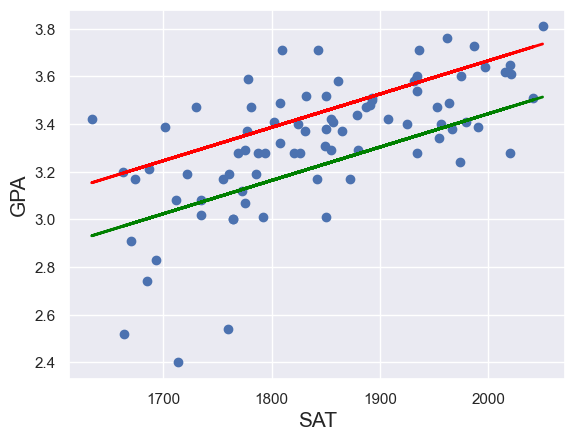

In [21]:
plt.scatter(data['SAT'], y)
yhat_no = 0.6439 + 0.0014 * data['SAT']
yhat_yes = 0.6439 + 0.0014 * data['SAT'] + 0.2226 
fig = plt.plot(data['SAT'], yhat_no, lw = 2, c = 'green')
fig = plt.plot(data['SAT'], yhat_yes, lw = 2, c = 'red')
plt.xlabel('SAT', fontsize = 15)
plt.ylabel('GPA', fontsize = 15)
plt.show()